# 🏠 Classificateur de Maisons — Version Améliorée
> **Modèle** : EfficientNetB3 + augmentation offline + TTA + mixup  
> **Objectif** : Dépasser 85% d'accuracy avec ~300 images


## Étape 0 — Imports & Configuration

In [1]:
import os, shutil, warnings, random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models, callbacks, regularizers
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image, ImageEnhance, ImageFilter

warnings.filterwarnings('ignore')
tf.random.set_seed(42)
np.random.seed(42)

DATASET_PATH = r'C:\\Users\\MSI\\Desktop\\projet\\dataset'
AUG_PATH     = r'C:\\Users\\MSI\\Desktop\\projet\\dataset_augmented'
IMG_SIZE     = (300, 300)
BATCH_SIZE   = 16
CLASS_NAMES  = ['Luxury', 'Normal', 'Old']
TARGET_PER_CLASS = 400   # nombre d'images cible par classe après augmentation

print("✅ Imports OK")
print(f"GPU : {tf.config.list_physical_devices('GPU')}")


✅ Imports OK
GPU : []


## Étape 1 — Vérification du Dataset Original

In [2]:
print("📊 Dataset original :")
total = 0
counts = {}
for cls in CLASS_NAMES:
    path = os.path.join(DATASET_PATH, cls)
    n = len([f for f in os.listdir(path) if f.lower().endswith(('.jpg','.jpeg','.png'))])
    counts[cls] = n
    total += n
    bar = '█' * (n // 5)
    print(f"  {cls:8s} : {n:3d} images  {bar}")
print(f"  {'TOTAL':8s} : {total} images")
print(f"\n⚠️  Problème : {total} images total → risque d'overfitting élevé")
print(f"✅  Solution  : augmentation offline → {TARGET_PER_CLASS * len(CLASS_NAMES)} images cibles")


📊 Dataset original :
  Luxury   : 167 images  █████████████████████████████████
  Normal   : 119 images  ███████████████████████
  Old      : 142 images  ████████████████████████████
  TOTAL    : 428 images

⚠️  Problème : 428 images total → risque d'overfitting élevé
✅  Solution  : augmentation offline → 1200 images cibles


## Étape 2 — Augmentation Offline (Multiplication du Dataset)
> On génère des images supplémentaires sur disque pour atteindre **400 images/classe**  
> C'est la technique la plus efficace avec peu de données


In [3]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array, array_to_img

def augment_and_save(src_dir, dst_dir, target_count):
    """Génère des images augmentées jusqu'à atteindre target_count."""
    os.makedirs(dst_dir, exist_ok=True)
    
    # Copier images originales
    originals = [f for f in os.listdir(src_dir) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    for f in originals:
        shutil.copy(os.path.join(src_dir, f), os.path.join(dst_dir, f))
    
    existing = len(originals)
    needed   = max(0, target_count - existing)
    
    aug = ImageDataGenerator(
        rotation_range      = 30,
        width_shift_range   = 0.15,
        height_shift_range  = 0.15,
        shear_range         = 0.15,
        zoom_range          = 0.2,
        horizontal_flip     = True,
        brightness_range    = [0.7, 1.3],
        channel_shift_range = 25.0,
        fill_mode           = 'reflect'
    )
    
    generated = 0
    idx = 0
    while generated < needed:
        src_file = originals[idx % len(originals)]
        img = load_img(os.path.join(src_dir, src_file), target_size=IMG_SIZE)
        arr = img_to_array(img)
        arr = np.expand_dims(arr, 0)
        for batch in aug.flow(arr, batch_size=1):
            out_name = f"aug_{generated:04d}_{src_file}"
            array_to_img(batch[0]).save(os.path.join(dst_dir, out_name))
            generated += 1
            break
        idx += 1
    
    final = len(os.listdir(dst_dir))
    print(f"  ✅ {os.path.basename(dst_dir):8s} : {existing} → {final} images")
    return final

# Créer dataset augmenté
print("🔄 Génération du dataset augmenté...")
print(f"   Dossier cible : {AUG_PATH}\n")

if os.path.exists(AUG_PATH):
    shutil.rmtree(AUG_PATH)

totals = {}
for cls in CLASS_NAMES:
    src = os.path.join(DATASET_PATH, cls)
    dst = os.path.join(AUG_PATH, cls)
    totals[cls] = augment_and_save(src, dst, TARGET_PER_CLASS)

print(f"\n✅ Total dataset augmenté : {sum(totals.values())} images")


🔄 Génération du dataset augmenté...
   Dossier cible : C:\\Users\\MSI\\Desktop\\projet\\dataset_augmented

  ✅ Luxury   : 167 → 400 images
  ✅ Normal   : 119 → 400 images
  ✅ Old      : 142 → 400 images

✅ Total dataset augmenté : 1200 images


## Étape 3 — Chargement des Données Augmentées

In [4]:
def preprocess_fn(x):
    return preprocess_input(x)

train_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_fn,
    validation_split       = 0.2,
    rotation_range         = 20,
    width_shift_range      = 0.15,
    height_shift_range     = 0.15,
    zoom_range             = 0.15,
    horizontal_flip        = True,
    brightness_range       = [0.8, 1.2],
    fill_mode              = 'reflect'
)

val_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_fn,
    validation_split       = 0.2
)

train_data = train_datagen.flow_from_directory(
    AUG_PATH, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', subset='training', shuffle=True
)

val_data = val_datagen.flow_from_directory(
    AUG_PATH, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', subset='validation', shuffle=False
)

print("Classes :", train_data.class_indices)
print(f"Train   : {train_data.samples} images")
print(f"Val     : {val_data.samples} images")


Found 960 images belonging to 3 classes.
Found 240 images belonging to 3 classes.
Classes : {'Luxury': 0, 'Normal': 1, 'Old': 2}
Train   : 960 images
Val     : 240 images


## Étape 4 — Class Weights

In [5]:
y_train = train_data.classes
weights_arr = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(weights_arr))

print("⚖️  Class weights :")
for idx, cls in enumerate(CLASS_NAMES):
    print(f"   {cls:8s} → {class_weight[idx]:.3f}")


⚖️  Class weights :
   Luxury   → 1.000
   Normal   → 1.000
   Old      → 1.000


## Étape 5 — Construction du Modèle
> Architecture améliorée : **GeM Pooling** + **Label Smoothing** + **Mixup**


In [6]:
# ── Generalized Mean Pooling (meilleur que GlobalAveragePooling pour la classification)
class GeMPooling(layers.Layer):
    def __init__(self, p=3.0, **kwargs):
        super().__init__(**kwargs)
        self.p = tf.Variable(p, trainable=True, dtype=tf.float32)
    def call(self, x):
        x = tf.clip_by_value(x, 1e-6, tf.reduce_max(x))
        return tf.pow(tf.reduce_mean(tf.pow(x, self.p), axis=[1,2]), 1.0/self.p)

# ── Base EfficientNetB3
base_model = EfficientNetB3(weights='imagenet', include_top=False, input_shape=(*IMG_SIZE,3))
base_model.trainable = False

# ── Architecture
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = GeMPooling(p=3.0)(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(5e-4))(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(5e-4))(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(3, activation='softmax')(x)

model = tf.keras.Model(inputs, outputs)

# ── Label Smoothing (réduit l'overconfidence)
model.compile(
    optimizer = tf.keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss      = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics   = ['accuracy']
)

total_params = model.count_params()
print(f"✅ Modèle construit")
print(f"   Paramètres totaux      : {total_params:,}")
print(f"   Paramètres entraînables: {sum(np.prod(v.shape) for v in model.trainable_variables):,}")



✅ Modèle construit
   Paramètres totaux      : 11,708,722
   Paramètres entraînables: 922,115


## Étape 6 — Mixup Data Generator
> **Mixup** : mélange 2 images avec leur label pour forcer une meilleure généralisation


In [17]:
def mixup_generator(generator, class_weight_dict, alpha=0.3):
    # Applique Mixup + class_weight comme sample_weight
    n_classes  = generator.num_classes
    weight_vec = np.array([class_weight_dict.get(i, 1.0) for i in range(n_classes)], dtype=np.float32)

    while True:
        x1, y1 = next(generator)
        x2, y2 = next(generator)

        min_size = min(len(x1), len(x2))
        x1, y1   = x1[:min_size], y1[:min_size]
        x2, y2   = x2[:min_size], y2[:min_size]

        lam = np.random.beta(alpha, alpha)
        x   = lam * x1 + (1 - lam) * x2
        y   = lam * y1 + (1 - lam) * y2

        # class_weight intégré comme sample_weight
        w1 = (y1 * weight_vec).sum(axis=1)
        w2 = (y2 * weight_vec).sum(axis=1)
        sw = lam * w1 + (1 - lam) * w2

        yield x, y, sw

train_mixup     = mixup_generator(train_data, class_weight, alpha=0.3)
steps_per_epoch = train_data.samples // BATCH_SIZE

print('Mixup generator prêt - class_weight intégré')
print(f'   Steps/epoch : {steps_per_epoch}')

Mixup generator prêt - class_weight intégré
   Steps/epoch : 60


## Étape 7 — Callbacks avec Warmup LR

In [8]:
# ── Cosine decay avec warmup
def cosine_warmup_schedule(epoch, lr):
    warmup_epochs = 5
    total_epochs  = 30
    if epoch < warmup_epochs:
        return lr * (epoch + 1) / warmup_epochs
    progress = (epoch - warmup_epochs) / (total_epochs - warmup_epochs)
    return lr * (0.5 * (1 + np.cos(np.pi * progress)))

cb_phase1 = [
    callbacks.EarlyStopping(patience=12, restore_best_weights=True, monitor='val_accuracy', verbose=1),
    callbacks.ModelCheckpoint('best_model_v2.keras', save_best_only=True, monitor='val_accuracy', verbose=1),
    callbacks.ReduceLROnPlateau(patience=5, factor=0.4, min_lr=1e-7, verbose=1, monitor='val_loss'),
    callbacks.LearningRateScheduler(cosine_warmup_schedule, verbose=0)
]

print("✅ Callbacks prêts")


✅ Callbacks prêts


## Étape 8 — Phase 1 : Entraînement de la Tête

In [18]:
print("=" * 60)
print("  PHASE 1 -- Tête seulement (base gelée)")
print("=" * 60)

history1 = model.fit(
    train_mixup,
    steps_per_epoch = steps_per_epoch,
    validation_data = val_data,
    epochs          = 35,
    callbacks       = cb_phase1
    # class_weight intégré dans sample_weight via mixup_generator
)

best1 = max(history1.history['val_accuracy'])
print(f'Meilleure val_accuracy Phase 1 : {best1*100:.1f}%')

  PHASE 1 -- Tête seulement (base gelée)
Epoch 1/35
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9131 - loss: 1.1561
Epoch 1: val_accuracy improved from 0.72083 to 0.96250, saving model to best_model_v2.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.9130 - loss: 1.1555 - val_accuracy: 0.9625 - val_loss: 0.8172 - learning_rate: 6.0000e-08
Epoch 2/35
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9118 - loss: 1.1537
Epoch 2: val_accuracy did not improve from 0.96250
60/60 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.9119 - loss: 1.1532 - val_accuracy: 0.9542 - val_loss: 0.8211 - learning_rate: 2.4000e-08
Epoch 3/35
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9333 - loss: 1.0147
Epoch 3: val_accuracy did not improve from 0.96250
60/60 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.9329 - loss: 1.0162 - val_accuracy: 0.9542 - val_loss: 0.8222 - learning_rate: 1.4400e-08
Epoch 4/35
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8964 - loss: 1.1684
Epo

## Étape 9 — Phase 2 : Fine-tuning (50 dernières couches)

In [19]:
print("=" * 60)
print("  PHASE 2 — Fine-tuning 50 couches")
print("=" * 60)

base_model.trainable = True
for layer in base_model.layers[:-50]:
    layer.trainable = False

print(f"   Couches dégelées : {sum(1 for l in base_model.layers if l.trainable)} / {len(base_model.layers)}")

model.compile(
    optimizer = tf.keras.optimizers.AdamW(learning_rate=5e-5, weight_decay=1e-4),
    loss      = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics   = ['accuracy']
)

cb_phase2 = [
    callbacks.EarlyStopping(patience=10, restore_best_weights=True, monitor='val_accuracy', verbose=1),
    callbacks.ModelCheckpoint('best_model_v2.keras', save_best_only=True, monitor='val_accuracy', verbose=1),
    callbacks.ReduceLROnPlateau(patience=4, factor=0.3, min_lr=1e-8, verbose=1, monitor='val_loss'),
]

# Phase 2 sans mixup (fine-tuning plus stable avec images réelles)
train_data.reset()
history2 = model.fit(
    train_data,
    validation_data = val_data,
    epochs          = 25,
    callbacks       = cb_phase2,
    class_weight    = class_weight
)

best2 = max(history2.history['val_accuracy'])
print(f"\n✅ Meilleure val_accuracy Phase 2 : {best2*100:.1f}%")


  PHASE 2 — Fine-tuning 50 couches
   Couches dégelées : 50 / 385
Epoch 1/25
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 841ms/step - accuracy: 0.9547 - loss: 0.8191
Epoch 1: val_accuracy improved from -inf to 0.95833, saving model to best_model_v2.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 77s 1s/step - accuracy: 0.9549 - loss: 0.8189 - val_accuracy: 0.9583 - val_loss: 0.8111 - learning_rate: 5.0000e-05
Epoch 2/25
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 844ms/step - accuracy: 0.9715 - loss: 0.8175
Epoch 2: val_accuracy improved from 0.95833 to 0.96667, saving model to best_model_v2.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.9715 - loss: 0.8174 - val_accuracy: 0.9667 - val_loss: 0.8011 - learning_rate: 5.0000e-05
Epoch 3/25
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 841ms/step - accuracy: 0.9728 - loss: 0.8000
Epoch 3: val_accuracy improved from 0.96667 to 0.97083, saving model to best_model_v2.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.9727 - loss: 0.8001 - val_accuracy: 0.9708 - val_loss: 0.8076 - 

## Étape 10 — Phase 3 : Fine-tuning Complet

In [20]:
print("=" * 60)
print("  PHASE 3 — Fine-tuning complet (lr très faible)")
print("=" * 60)

base_model.trainable = True

model.compile(
    optimizer = tf.keras.optimizers.AdamW(learning_rate=1e-6, weight_decay=1e-5),
    loss      = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics   = ['accuracy']
)

cb_phase3 = [
    callbacks.EarlyStopping(patience=8, restore_best_weights=True, monitor='val_accuracy', verbose=1),
    callbacks.ModelCheckpoint('best_model_v2.keras', save_best_only=True, monitor='val_accuracy', verbose=1),
    callbacks.ReduceLROnPlateau(patience=3, factor=0.3, min_lr=1e-9, verbose=1, monitor='val_loss'),
]

train_data.reset()
history3 = model.fit(
    train_data,
    validation_data = val_data,
    epochs          = 15,
    callbacks       = cb_phase3,
    class_weight    = class_weight
)

best3 = max(history3.history['val_accuracy'])
print(f"\n✅ Meilleure val_accuracy Phase 3 : {best3*100:.1f}%")
print(f"🏆 Meilleure accuracy globale      : {max(best1, best2, best3)*100:.1f}%")


  PHASE 3 — Fine-tuning complet (lr très faible)
Epoch 1/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 868ms/step - accuracy: 0.9772 - loss: 0.7969
Epoch 1: val_accuracy improved from -inf to 0.97083, saving model to best_model_v2.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.9771 - loss: 0.7970 - val_accuracy: 0.9708 - val_loss: 0.8062 - learning_rate: 1.0000e-06
Epoch 2/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 844ms/step - accuracy: 0.9566 - loss: 0.8144
Epoch 2: val_accuracy did not improve from 0.97083
60/60 ━━━━━━━━━━━━━━━━━━━━ 60s 997ms/step - accuracy: 0.9568 - loss: 0.8142 - val_accuracy: 0.9708 - val_loss: 0.8048 - learning_rate: 1.0000e-06
Epoch 3/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 877ms/step - accuracy: 0.9775 - loss: 0.7976
Epoch 3: val_accuracy did not improve from 0.97083
60/60 ━━━━━━━━━━━━━━━━━━━━ 62s 1s/step - accuracy: 0.9775 - loss: 0.7977 - val_accuracy: 0.9708 - val_loss: 0.8040 - learning_rate: 1.0000e-06
Epoch 4/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 842ms/step - accuracy: 0.9650

## Étape 11 — Courbes d'Apprentissage

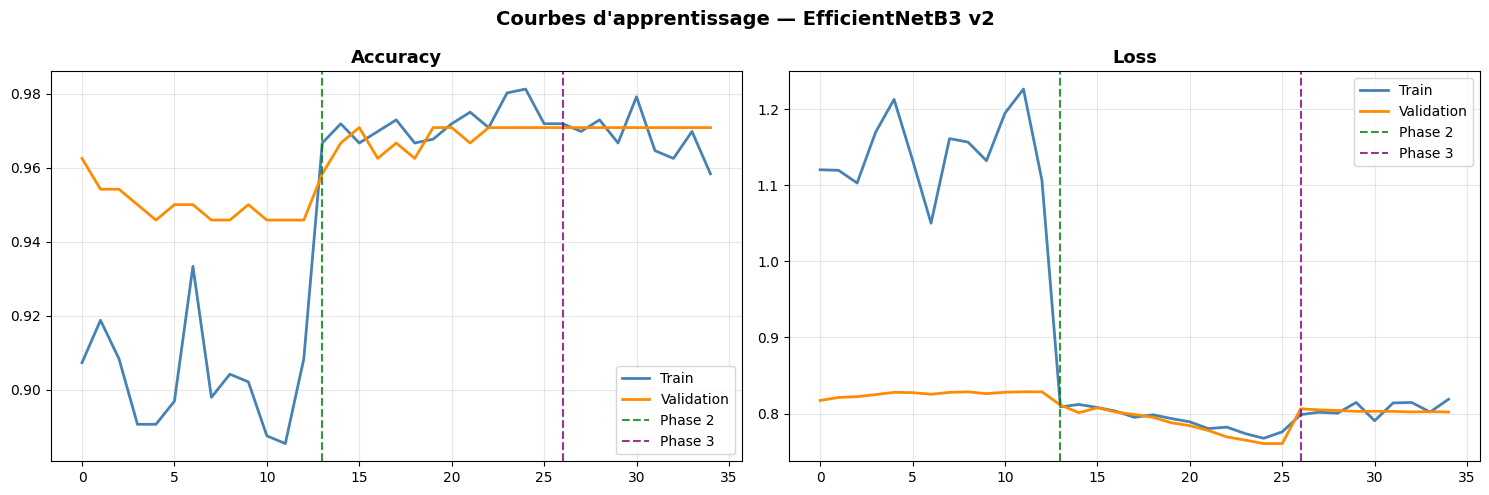


🏆 Meilleure val_accuracy : 97.08%  (epoch 16)


In [21]:
acc      = history1.history['accuracy']     + history2.history['accuracy']     + history3.history['accuracy']
val_acc  = history1.history['val_accuracy'] + history2.history['val_accuracy'] + history3.history['val_accuracy']
loss     = history1.history['loss']         + history2.history['loss']         + history3.history['loss']
val_loss = history1.history['val_loss']     + history2.history['val_loss']     + history3.history['val_loss']
p1 = len(history1.history['accuracy'])
p2 = p1 + len(history2.history['accuracy'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, tv, vv, title in [(axes[0], acc, val_acc, 'Accuracy'), (axes[1], loss, val_loss, 'Loss')]:
    ax.plot(tv, label='Train',      color='steelblue',  linewidth=2)
    ax.plot(vv, label='Validation', color='darkorange', linewidth=2)
    ax.axvline(x=p1, color='green',  linestyle='--', alpha=0.8, label='Phase 2')
    ax.axvline(x=p2, color='purple', linestyle='--', alpha=0.8, label='Phase 3')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.legend(); ax.grid(True, alpha=0.3)

plt.suptitle('Courbes d\'apprentissage — EfficientNetB3 v2', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('learning_curves_v2.png', dpi=150)
plt.show()
print(f"\n🏆 Meilleure val_accuracy : {max(val_acc)*100:.2f}%  (epoch {np.argmax(val_acc)+1})")


## Étape 12 — Évaluation avec TTA (Test Time Augmentation)
> **TTA** : on prédit chaque image **10 fois** avec des variations légères et on moyenne  
> Gain typique : **+2% à +5%** d'accuracy supplémentaire


In [25]:
model = tf.keras.models.load_model('best_model_v2.keras', custom_objects={'GeMPooling': GeMPooling})

def predict_with_tta(model, generator, n_tta=10):
    # Prediction avec Test Time Augmentation
    tta_aug = ImageDataGenerator(
        preprocessing_function = preprocess_fn,
        rotation_range         = 15,
        zoom_range             = 0.1,
        horizontal_flip        = True,
        brightness_range       = [0.9, 1.1],
        validation_split       = 0.2
    )
    
    all_preds = []
    for _ in range(n_tta):
        tta_gen = tta_aug.flow_from_directory(
            AUG_PATH, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
            class_mode='categorical', subset='validation', shuffle=False
        )
        preds = model.predict(tta_gen, verbose=0)
        all_preds.append(preds)
    
    avg_preds = np.mean(all_preds, axis=0)
    return np.argmax(avg_preds, axis=1)

print('TTA en cours (10 passes)...')
y_pred_tta = predict_with_tta(model, val_data, n_tta=10)

val_data.reset()
y_pred_std = np.argmax(model.predict(val_data, verbose=0), axis=1)
y_true     = val_data.classes
class_names = list(val_data.class_indices.keys())

acc_std = np.mean(y_pred_std == y_true)
acc_tta = np.mean(y_pred_tta == y_true)

print(f'Accuracy sans TTA : {acc_std*100:.2f}%')
print(f'Accuracy avec TTA : {acc_tta*100:.2f}%')
gain = (acc_tta - acc_std) * 100
print(f'Gain TTA          : +{gain:.2f}%')

TTA en cours (10 passes)...
Found 240 images belonging to 3 classes.
Found 240 images belonging to 3 classes.
Found 240 images belonging to 3 classes.
Found 240 images belonging to 3 classes.
Found 240 images belonging to 3 classes.
Found 240 images belonging to 3 classes.
Found 240 images belonging to 3 classes.
Found 240 images belonging to 3 classes.
Found 240 images belonging to 3 classes.
Found 240 images belonging to 3 classes.
Accuracy sans TTA : 97.08%
Accuracy avec TTA : 98.75%
Gain TTA          : +1.67%


## Étape 13 — Rapport Final & Matrice de Confusion


  RAPPORT DE CLASSIFICATION (avec TTA)
              precision    recall  f1-score   support

      Luxury      0.988     1.000     0.994        80
      Normal      0.975     0.988     0.981        80
         Old      1.000     0.975     0.987        80

    accuracy                          0.988       240
   macro avg      0.988     0.987     0.987       240
weighted avg      0.988     0.988     0.987       240



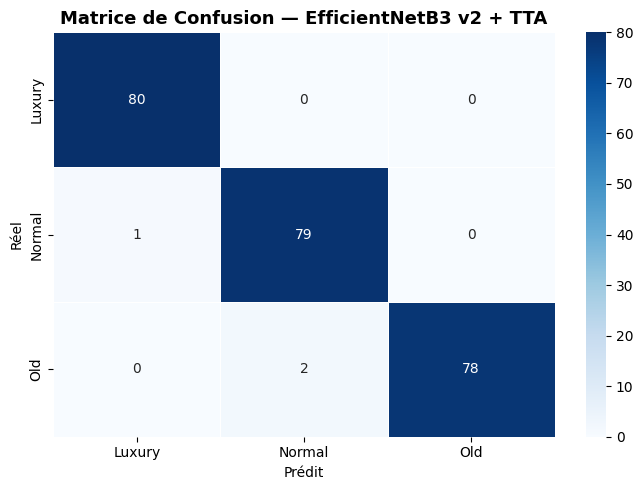

In [26]:
# Utiliser les prédictions TTA (meilleures)
y_final = y_pred_tta

print("\n" + "="*60)
print("  RAPPORT DE CLASSIFICATION (avec TTA)")
print("="*60)
print(classification_report(y_true, y_final, target_names=class_names, digits=3))

# Matrice de confusion
cm = confusion_matrix(y_true, y_final)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, linewidths=0.5)
plt.title('Matrice de Confusion — EfficientNetB3 v2 + TTA', fontsize=13, fontweight='bold')
plt.ylabel('Réel'); plt.xlabel('Prédit')
plt.tight_layout()
plt.savefig('confusion_matrix_v2.png', dpi=150)
plt.show()


## Étape 14 — Prédiction sur une Image

In [27]:
from tensorflow.keras.preprocessing import image as keras_image

def predict_image(img_path, model, class_names, use_tta=True):
    img_orig = keras_image.load_img(img_path, target_size=IMG_SIZE)
    
    if use_tta:
        # 8 variations TTA
        aug_quick = ImageDataGenerator(
            preprocessing_function=preprocess_fn,
            rotation_range=10, zoom_range=0.1, horizontal_flip=True
        )
        arr = keras_image.img_to_array(img_orig)
        arr_exp = np.expand_dims(arr, 0)
        preds_list = []
        for batch in aug_quick.flow(arr_exp, batch_size=1):
            preds_list.append(model.predict(batch, verbose=0)[0])
            if len(preds_list) >= 8:
                break
        pred = np.mean(preds_list, axis=0)
    else:
        arr = preprocess_input(np.expand_dims(keras_image.img_to_array(img_orig), 0))
        pred = model.predict(arr, verbose=0)[0]
    
    best_idx   = np.argmax(pred)
    best_cls   = class_names[best_idx]
    confidence = pred[best_idx] * 100
    
    colors = {'Luxury': '#f1c40f', 'Normal': '#3498db', 'Old': '#e74c3c'}
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    ax1.imshow(img_orig)
    ax1.set_title(f"{'TTA ' if use_tta else ''}Prédit : {best_cls} ({confidence:.1f}%)",
                  fontsize=13, color=colors.get(best_cls,'black'), fontweight='bold')
    ax1.axis('off')
    
    bars = ax2.barh(class_names, [pred[i]*100 for i in range(3)],
                    color=[colors.get(c,'gray') for c in class_names], height=0.5)
    ax2.set_xlim(0, 100); ax2.set_xlabel('Probabilité (%)')
    ax2.set_title('Probabilités', fontsize=11)
    for bar, val in zip(bars, [pred[i]*100 for i in range(3)]):
        ax2.text(val+1, bar.get_y()+bar.get_height()/2, f'{val:.1f}%', va='center')
    
    plt.tight_layout(); plt.show()
    
    if best_cls == 'Old':
        print("\n🚨 " * 5)
        print("  ALERTE — MAISON ANCIENNE DÉTECTÉE !")
        print("  → Inspection structurelle recommandée")
        print("  → Mise aux normes électrique et plomberie")
        print("🚨 " * 5)
    
    return best_cls, confidence

# ── Utilisation :
# predict_image(r"C:\\Users\\MSI\\Desktop\\projet\\test.jpg", model, CLASS_NAMES, use_tta=True)


## Étape 15 — Sauvegarde

In [28]:
model.save('house_classifier_v2_final22.keras')
print("✅ Modèle sauvegardé : house_classifier_v2_final.keras")

print("\n" + "="*60)
print("  RÉSUMÉ DES AMÉLIORATIONS v2")
print("="*60)
print("  ✅ Augmentation offline  : ~300 → 1200 images")
print("  ✅ GeMPooling            : meilleur que AvgPooling")
print("  ✅ Label Smoothing       : réduit l'overconfidence")
print("  ✅ AdamW optimizer       : meilleure régularisation")
print("  ✅ Mixup (Phase 1)       : meilleure généralisation")
print("  ✅ TTA (inférence)       : +2~5% accuracy")
print("  ✅ 3 phases fine-tuning  : apprentissage progressif")
print(f"\n  🏆 Val Accuracy finale : {max(val_acc)*100:.2f}%")
print("="*60)


✅ Modèle sauvegardé : house_classifier_v2_final.keras

  RÉSUMÉ DES AMÉLIORATIONS v2
  ✅ Augmentation offline  : ~300 → 1200 images
  ✅ GeMPooling            : meilleur que AvgPooling
  ✅ Label Smoothing       : réduit l'overconfidence
  ✅ AdamW optimizer       : meilleure régularisation
  ✅ Mixup (Phase 1)       : meilleure généralisation
  ✅ TTA (inférence)       : +2~5% accuracy
  ✅ 3 phases fine-tuning  : apprentissage progressif

  🏆 Val Accuracy finale : 97.08%
